# Tugas 03: Regresi Linear Sederhana dan Berganda pada Data Biaya Asuransi Kesehatan
**Pengantar Sains Data · Universitas Matana · Data Kesehatan**

Anggota kelompok: Satria Ramadhani, Immanuel Machello Sutanto, Joe Alexander

**Dataset:** Medical Cost Personal Datasets, 1338 observasi, 7 variabel.

**Ruang lingkup:** data observasional. Koefisien model menunjukkan **asosiasi**, bukan sebab-akibat.

========================================
# **REGRESI LINEAR SEDERHANA**
========================================

## 1. Setup
Semua library dimuat di satu tempat. Jalankan sel ini lebih dulu.

In [ ]:
# Cell 1: import library
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

## 2. Pendahuluan
Biaya asuransi kesehatan berbeda jauh antar orang. Perusahaan asuransi perlu memperkirakan biaya seseorang dari karakteristik yang mudah diketahui, misalnya usia, BMI, dan kebiasaan merokok.

**Pertanyaan SLR:** seberapa jauh **usia** menjelaskan **biaya asuransi tahunan**?

**Tujuan:**
1. Membangun model regresi linear sederhana dengan satu prediktor numerik.
2. Mengukur kualitasnya pada data uji (MAE, RMSE, R²).
3. Memeriksa pola kesalahan lewat plot residual.

**Sumber data:** Brett Lantz, *Machine Learning with R*, versi Kaggle `mirichoi0218/insurance`.

## 3. Preview Data
Kita muat data, lalu pastikan bentuknya sesuai harapan: 1338 baris dan 7 kolom.

In [ ]:
# Cell 2: muat dataset dan cek bentuk
path = kagglehub.dataset_download("mirichoi0218/insurance")
df = pd.read_csv(os.path.join(path, "insurance.csv"))
print(df.shape)
df.head()

Using Colab cache for faster access to the 'insurance' dataset.
(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 4. Penjelasan Variabel Asli

| Variabel | Tipe | Keterangan | Dipakai di |
|---|---|---|---|
| `age` | Numerik (integer) | Usia pemegang polis, tahun | SLR (X), MLR |
| `sex` | Kategori (2 level) | `male` / `female` | MLR |
| `bmi` | Numerik (float) | Body Mass Index, kg/m² | MLR |
| `children` | Numerik (integer) | Jumlah tanggungan anak | MLR |
| `smoker` | Kategori (2 level) | `yes` / `no` | MLR |
| `region` | Kategori (4 level) | `northeast`, `northwest`, `southeast`, `southwest` | MLR |
| `charges` | Numerik (float) | Total biaya asuransi tahunan, USD | **Y** |

## 5. Statistik Deskriptif
Tiga pemeriksaan: tipe data, missing values, dan ringkasan angka.

In [ ]:
# Cell 3: tipe data dan missing values
print("Tipe data:")
df.info()

print("\nMissing values per kolom:")
print(df.isna().sum())

Tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing values per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [ ]:
# Cell 4: statistik deskriptif kolom numerik
print("\nStatistik deskriptif (kolom numerik):")
df.describe().round(2)


Statistik deskriptif (kolom numerik):


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


**Insight:**
- Tidak ada missing values, jadi data langsung bisa dipakai.
- `charges` punya rata-rata 13.270 USD dan median 9.382 USD. Rata-rata lebih besar dari median, tanda distribusi **miring ke kanan**. Nilai maksimum 63.770 USD jauh di atas kuartil ketiga (16.640 USD).
- `age` berkisar 18 sampai 64 tahun (rata-rata 39). `bmi` rata-rata 30,66 dengan median 30,40, jadi relatif simetris.

### Hubungan `charges` dengan variabel lain
Rata-rata `charges` per kelompok kategori, lalu korelasi dengan variabel numerik.

In [ ]:
# Cell 5: rata-rata charges per kategori
for col in ["sex", "smoker", "region"]:
    print(f"\nRata-rata charges per {col}:")
    print(df.groupby(col)["charges"].mean().round(2))


Rata-rata charges per sex:
sex
female    12569.58
male      13956.75
Name: charges, dtype: float64

Rata-rata charges per smoker:
smoker
no      8434.27
yes    32050.23
Name: charges, dtype: float64

Rata-rata charges per region:
region
northeast    13406.38
northwest    12417.58
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64


In [ ]:
# Cell 6: korelasi variabel numerik dengan charges
print("\nKorelasi dengan charges:")
print(df[["age", "bmi", "children", "charges"]].corr()["charges"].round(3))


Korelasi dengan charges:
age         0.299
bmi         0.198
children    0.068
charges     1.000
Name: charges, dtype: float64


**Insight:**
- `smoker` menunjukkan selisih terbesar: perokok rata-rata 32.050 USD, bukan perokok 8.434 USD (hampir empat kali lipat).
- `sex` (12.570 vs 13.957 USD) dan `region` (12.347 sampai 14.735 USD) selisihnya kecil.
- Di antara variabel numerik, `age` berkorelasi paling kuat dengan `charges` (0,299), diikuti `bmi` (0,198) dan `children` (0,068).

## 6. Alasan Memilih Y dan X
- **Y = `charges`.** Tujuan analisis adalah memperkirakan biaya asuransi. Variabelnya numerik kontinu, sesuai syarat regresi linear.
- **X = `age`.** Korelasinya paling kuat di antara variabel numerik (0,299), mudah diukur, dan numerik sehingga langsung cocok untuk SLR.
- **`smoker` tidak dipakai di SLR.** Variabelnya kategori dan pengaruhnya besar, jadi lebih tepat dimasukkan di regresi berganda.

## 7. Scatter Plot (lihat sebelum memodelkan)
Baca **arah** (naik atau turun) dan **penyebaran** titik. Tren naik tidak berarti semua titik berada di satu garis.

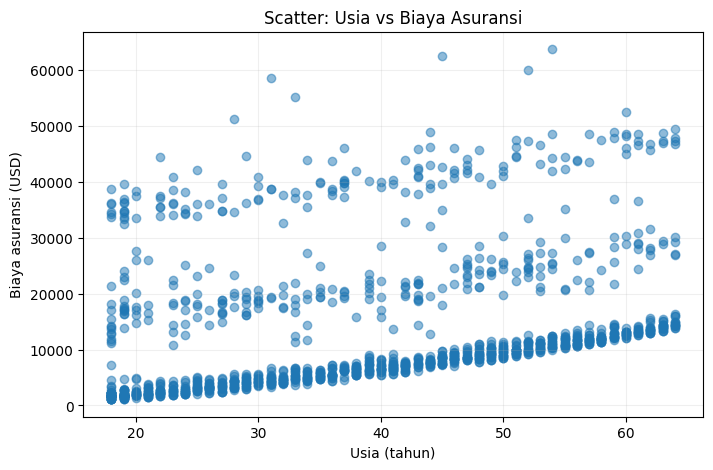

In [ ]:
# Cell 7: scatter plot age vs charges
plt.figure(figsize=(8, 5))
plt.scatter(df["age"], df["charges"], alpha=0.5)
plt.xlabel("Usia (tahun)")
plt.ylabel("Biaya asuransi (USD)")
plt.title("Scatter: Usia vs Biaya Asuransi")
plt.grid(alpha=0.2)
plt.show()

### Heatmap Correlation (variabel numerik)
Heatmap berikut menampilkan korelasi Pearson antara variabel numerik `age`, `bmi`, `children`, dan `charges`. Variabel kategori (`sex`, `smoker`, dan `region`) tidak dimasukkan ke heatmap ini karena memerlukan pengodean tersendiri.

In [ ]:
# Cell tambahan: heatmap korelasi variabel numerik
kolom_korelasi = ["age", "bmi", "children", "charges"]
matriks_korelasi = df[kolom_korelasi].corr(method="pearson")

fig, ax = plt.subplots(figsize=(6, 5))
gambar = ax.imshow(matriks_korelasi, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(np.arange(len(kolom_korelasi)))
ax.set_yticks(np.arange(len(kolom_korelasi)))
ax.set_xticklabels(kolom_korelasi, rotation=30, ha="right")
ax.set_yticklabels(kolom_korelasi)

for i in range(len(kolom_korelasi)):
    for j in range(len(kolom_korelasi)):
        ax.text(j, i, f"{matriks_korelasi.iloc[i, j]:.3f}",
                ha="center", va="center", color="black")

plt.colorbar(gambar, ax=ax, label="Korelasi Pearson")
ax.set_title("Heatmap Correlation Variabel Numerik")
plt.tight_layout()
plt.show()

**Interpretasi heatmap:**
- Korelasi numerik paling kuat dengan `charges` adalah `age` (0,299), diikuti `bmi` (0,198) dan `children` (0,068).
- Ketiganya menunjukkan arah positif, tetapi kekuatannya relatif lemah.
- Heatmap ini hanya mencakup variabel numerik. Hubungan variabel kategori tetap dibahas melalui analisis kelompok dan model regresi.

**Insight:**
- Tren naik tipis: biaya cenderung lebih tinggi pada usia yang lebih tua.
- Titik **tidak** menyebar di sekitar satu garis. Titik membentuk **tiga pita horizontal**: pita padat di bawah (sekitar 1.000 sampai 16.000 USD) yang naik pelan mengikuti usia, pita tengah (sekitar 15.000 sampai 30.000 USD), dan pita atas (sekitar 33.000 sampai 50.000 USD, dengan beberapa titik di atas 55.000 USD).
- Dugaan: ada faktor lain yang memisahkan ketiga kelompok ini, kemungkinan `smoker`. Dugaan ini diuji di regresi berganda.

## 8. Split Train dan Test (80 : 20)
- **Train (80%)** dipakai untuk melatih model. **Test (20%)** hanya untuk menilai prediksi pada data yang tidak dipakai saat fitting.
- `X` ditulis dengan dua kurung siku (`df[["age"]]`) karena scikit-learn meminta tabel, bukan satu kolom.
- `random_state=42` membuat hasil sama setiap kali dijalankan.

In [ ]:
# Cell 8: bagi data
X = df[["age"]]
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1070, 1) | Test: (268, 1)


## 9. Fitting Model SLR
`LinearRegression` mencari garis yang meminimalkan jumlah kuadrat kesalahan pada data **train**. Data test tidak dipakai di langkah ini.

In [ ]:
# Cell 9: latih model dan baca koefisien
model_slr = LinearRegression()
model_slr.fit(X_train, y_train)

print("Intersep (b0):", round(model_slr.intercept_, 2))
print("Koefisien age (b1):", round(model_slr.coef_[0], 2))
b0 = float(model_slr.intercept_)
b1 = float(model_slr.coef_[0])
print(f"Persamaan: charges = {b0:.2f} + {b1:.2f} × age")

Intersep (b0): 3876.93
Koefisien age (b1): 240.6
Persamaan: charges = 3876.93 + 240.60 × age


## 10. Evaluasi pada Test Set (MAE, RMSE, R²)
Semua metrik dihitung pada **test set** (268 baris).
- **MAE:** rata-rata selisih absolut prediksi dan nilai asli, dalam USD.
- **RMSE:** akar rata-rata kuadrat selisih, dalam USD. Selisih besar dihukum lebih berat.
- **R²:** proporsi variasi `charges` yang dijelaskan model.

In [ ]:
# Cell 10: prediksi dan tabel metrik
y_pred_slr = model_slr.predict(X_test)

mae_slr = mean_absolute_error(y_test, y_pred_slr)
rmse_slr = np.sqrt(mean_squared_error(y_test, y_pred_slr))
r2_slr = r2_score(y_test, y_pred_slr)

hasil_slr = pd.DataFrame(
    {"MAE (USD)": [mae_slr], "RMSE (USD)": [rmse_slr], "R²": [r2_slr]},
    index=["SLR: age"],
).round(4)
hasil_slr

,MAE (USD),RMSE (USD),R²
SLR: age,9173.2582,11661.216,0.1241


## 11. Interpretasi Model dan Persamaan
**Persamaan:** `charges = 3876,93 + 240,60 × age`

- **Slope (b₁ = 240,60):** setiap pertambahan usia 1 tahun, rata-rata prediksi biaya naik sekitar 240,60 USD. Ini asosiasi pada model satu prediktor, bukan bukti sebab-akibat.
- **Intersep (b₀ = 3876,93):** prediksi untuk usia 0 tahun. Tidak ada pelanggan berusia 0 (data mulai dari 18), jadi angka ini hanya titik awal garis dan tidak punya makna praktis.
- **R² = 0,1241:** usia hanya menjelaskan sekitar 12% variasi biaya. Sisanya berasal dari faktor yang belum masuk model.
- **MAE = 9.173 USD** dan **RMSE = 11.661 USD:** rata-rata tebakan meleset sekitar 9.000 USD, padahal rata-rata biaya 13.270 USD. RMSE yang lebih besar dari MAE menandakan ada tebakan yang meleset sangat jauh.

*(Angka di atas berasal dari run dengan `random_state=42`. Cocokkan dengan output sel di atas.)*

## 12. Visualisasi
### 12a. Garis model di atas scatter
Garis digambar dari grid usia yang **terurut** (`np.linspace`) supaya mulus. Menyambung prediksi dari `X` acak langsung akan membuat garis zig-zag.

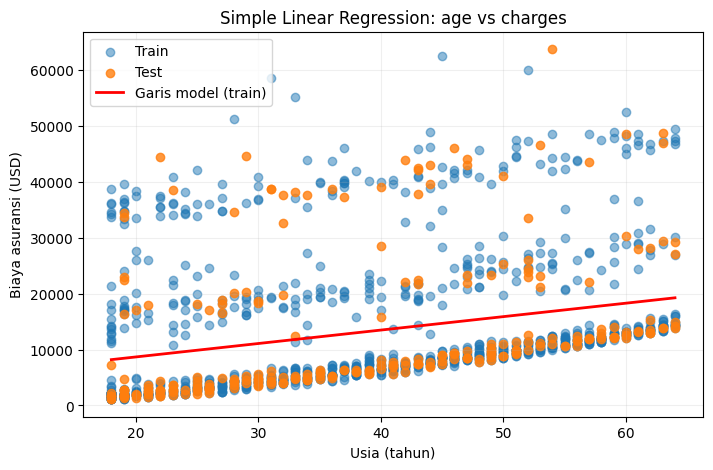

In [ ]:
# Cell 11: garis model dan scatter
x_grid = pd.DataFrame({"age": np.linspace(df["age"].min(), df["age"].max(), 100)})
y_grid = model_slr.predict(x_grid)

plt.figure(figsize=(8, 5))
plt.scatter(X_train["age"], y_train, label="Train", alpha=0.5)
plt.scatter(X_test["age"], y_test, label="Test", alpha=0.8)
plt.plot(x_grid["age"], y_grid, color="red", linewidth=2, label="Garis model (train)")
plt.xlabel("Usia (tahun)")
plt.ylabel("Biaya asuransi (USD)")
plt.title("Simple Linear Regression: age vs charges")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Insight:**
- Garis naik dari sekitar 8.200 USD (usia 18) ke sekitar 19.300 USD (usia 64), sesuai persamaan.
- Garis berada di celah antara pita bawah dan pita tengah, jadi dekat dengan sangat sedikit titik. Pita bawah (mayoritas titik) berada di bawah garis, sedangkan pita atas berada jauh di atasnya.
- Titik test (oranye) menyebar di ketiga pita seperti titik train, jadi masalahnya bukan pembagian data. Satu garis memang tidak cukup untuk tiga kelompok.

### 12b. Plot residual
Residual = **aktual − prediksi**. Titik yang sehat tersebar acak di sekitar garis nol tanpa pola. Ini pemeriksaan awal, bukan uji asumsi formal.

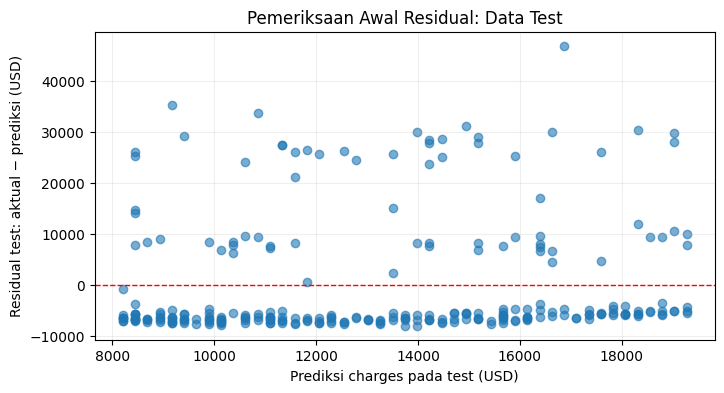

In [ ]:
# Cell 12: plot residual pada data test
residual_test = y_test.to_numpy() - y_pred_slr

plt.figure(figsize=(8, 4))
plt.scatter(y_pred_slr, residual_test, alpha=0.6)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.xlabel("Prediksi charges pada test (USD)")
plt.ylabel("Residual test: aktual − prediksi (USD)")
plt.title("Pemeriksaan Awal Residual: Data Test")
plt.grid(alpha=0.2)
plt.show()

**Insight:**
- Residual **tidak** tersebar acak di sekitar nol. Titik membentuk dua kelompok.
- Kelompok besar berada di bawah nol, sekitar −5.000 sampai −8.000 USD. Untuk pelanggan berbiaya rendah, model memprediksi terlalu tinggi.
- Kelompok lain berada di atas nol, sekitar 5.000 sampai 47.000 USD. Untuk pelanggan berbiaya tinggi, model memprediksi terlalu rendah.
- Hampir tidak ada titik di sekitar garis nol. Pola ini menandakan model satu prediktor melewatkan faktor penting, konsisten dengan R² 0,1241 dan RMSE yang lebih besar dari MAE.

## 13. Ringkasan SLR
**Yang dilakukan:** muat data, periksa, scatter plot, split 80:20, fit pada train, evaluasi pada test, interpretasi, plot residual.

**Temuan utama:** usia berasosiasi positif dengan biaya asuransi (sekitar +240,60 USD per tahun), tetapi model satu prediktor lemah (R² = 0,1241).

**Keterbatasan:**
1. Satu prediktor tidak menangkap faktor lain. Scatter menunjukkan tiga pita biaya yang tidak bisa dijelaskan usia saja, dan dugaan kuatnya adalah kebiasaan merokok.
2. `charges` miring ke kanan, jadi kesalahan prediksi cenderung besar pada biaya tinggi.
3. Hasil berlaku untuk rentang usia 18 sampai 64. Jangan mengekstrapolasi di luar rentang itu.
4. Data observasional: asosiasi, bukan kausalitas.

=======================================
# **REGRESI LINEAR BERGANDA**
=======================================

## 14. Pendahuluan Regresi Berganda
Di SLR, usia saja hanya menjelaskan sekitar 12% variasi biaya (R² = 0,1241), dan scatter plot menunjukkan tiga pita biaya yang tidak bisa dijelaskan usia. Bagian ini memakai **semua variabel** sebagai prediktor.

**Pertanyaan MLR:** seberapa baik usia, BMI, jumlah anak, jenis kelamin, status merokok, dan wilayah **bersama-sama** menjelaskan biaya asuransi tahunan?

**Tujuan:**
1. Membangun model regresi berganda dengan 6 prediktor (3 numerik, 3 kategori).
2. Membandingkannya dengan SLR pada test set yang sama.
3. Membaca koefisien dengan kategori referensi yang jelas.
4. Memeriksa residual lewat plot diagnostik.

## 15. Alasan Memilih Y dan X (MLR)
- **Y = `charges`**, sama seperti SLR, supaya perbandingan kedua model adil.
- **X = semua enam variabel:** `age`, `bmi`, `children` (numerik) dan `smoker`, `sex`, `region` (kategori).
- **`smoker`:** selisih rata-rata terbesar (32.050 vs 8.434 USD) dan dugaan penyebab tiga pita di scatter SLR.
- **`age` dan `bmi`:** berkorelasi positif dengan `charges` (0,299 dan 0,198).
- **`children`, `sex`, `region`:** hubungan sederhananya lemah, tetapi tetap dimasukkan. Pengaruh sebuah variabel bisa berubah ketika variabel lain ditahan tetap, dan kontribusinya kita baca lewat koefisien.
- Tugas ini tidak melakukan seleksi variabel. Semua prediktor dimasukkan sekaligus.

## 16. Eksplorasi Tambahan untuk MLR
Dua plot untuk melengkapi scatter di bagian SLR: distribusi `charges` dan perbandingan `charges` antara perokok dan bukan perokok.

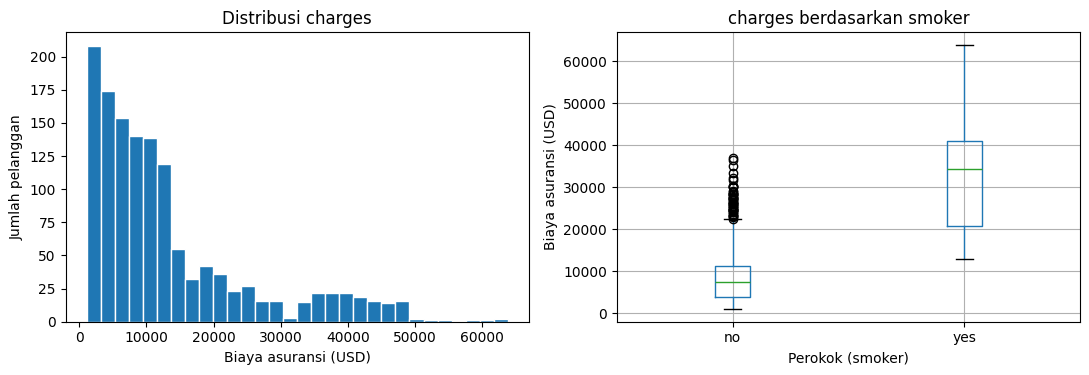

In [ ]:
# Cell 13: dua plot EDA tambahan
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(df["charges"], bins=30, edgecolor="white")
ax[0].set(xlabel="Biaya asuransi (USD)", ylabel="Jumlah pelanggan",
          title="Distribusi charges")

df.boxplot(column="charges", by="smoker", ax=ax[1])
ax[1].set(xlabel="Perokok (smoker)", ylabel="Biaya asuransi (USD)",
          title="charges berdasarkan smoker")

plt.suptitle("")
plt.tight_layout()
plt.show()

**Insight:**
- Histogram miring ke kanan: sebagian besar pelanggan berbiaya rendah, sebagian kecil sangat tinggi. Ini konsisten dengan rata-rata (13.270 USD) yang lebih besar dari median (9.382 USD).
- Kotak perokok berada jauh di atas kotak bukan perokok, sesuai selisih rata-rata 32.050 vs 8.434 USD.
- Kedua hal ini menjadi alasan visual untuk memasukkan `smoker` ke model.

## 17. Persiapan Fitur dan Split (80 : 20)
Model linear hanya menerima angka, jadi kolom kategori diubah dengan **one-hot encoding**. Parameter `drop='first'` membuang satu kategori per variabel sebagai **referensi**, supaya tidak ada informasi ganda (multikolinearitas sempurna).

| Variabel | Kategori referensi (dibuang) | Kolom dummy yang dibuat |
|---|---|---|
| `smoker` | `no` | `smoker_yes` |
| `sex` | `female` | `sex_male` |
| `region` | `northeast` | `region_northwest`, `region_southeast`, `region_southwest` |

- Semua transformasi dibungkus dalam **Pipeline**, jadi encoder hanya belajar dari data train dan tidak melihat data test.
- `random_state=42` dan `test_size=0.2` sama seperti SLR, jadi baris train dan test **identik**. Perbandingan SLR vs MLR menjadi adil.

In [ ]:
# Cell 14: pisahkan X dan Y, lalu split yang sama dengan SLR
X_mlr = df.drop(columns=["charges"])
y_mlr = df["charges"]

X_train_mlr, X_test_mlr, y_train_mlr, y_test_mlr = train_test_split(
    X_mlr, y_mlr, test_size=0.2, random_state=42
)
print("Shape Train:", X_train_mlr.shape, "| Shape Test:", X_test_mlr.shape)

assert X_train_mlr.shape == (1070, 6) and X_test_mlr.shape == (268, 6)
assert X_test_mlr.index.equals(X_test.index)   # baris test sama dengan SLR

Shape Train: (1070, 6) | Shape Test: (268, 6)


In [ ]:
# Cell 15: preprocessor dan pipeline
num_cols = ["age", "bmi", "children"]
cat_cols = ["smoker", "sex", "region"]

preprocessor = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

model_mlr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])
model_mlr

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['smoker', 'sex',
                                                   'region'])])),
                ('regressor', LinearRegression())])

## 18. Fitting Model MLR
Pipeline menjalankan dua langkah berurutan pada data **train**: encoding kategori, lalu `LinearRegression`. Data test tidak dipakai di langkah ini.

In [ ]:
# Cell 16: latih model MLR
model_mlr.fit(X_train_mlr, y_train_mlr)
print("Model MLR berhasil dilatih.")

Model MLR berhasil dilatih.


## 19. Evaluasi pada Test Set dan Perbandingan dengan SLR
Metrik dihitung pada test set yang sama (268 baris) seperti SLR.

In [ ]:
# Cell 17: prediksi, tabel metrik MLR, dan perbandingan dengan SLR
y_pred_mlr = model_mlr.predict(X_test_mlr)

mae_mlr = mean_absolute_error(y_test_mlr, y_pred_mlr)
rmse_mlr = np.sqrt(mean_squared_error(y_test_mlr, y_pred_mlr))
r2_mlr = r2_score(y_test_mlr, y_pred_mlr)

hasil_mlr = pd.DataFrame(
    {"MAE (USD)": [mae_mlr], "RMSE (USD)": [rmse_mlr], "R²": [r2_mlr]},
    index=["MLR: 6 prediktor"],
).round(4)

perbandingan = pd.concat([hasil_slr, hasil_mlr])
print(f"MAE turun {1 - mae_mlr / mae_slr:.1%} dan RMSE turun {1 - rmse_mlr / rmse_slr:.1%} dibanding SLR")
perbandingan

MAE turun 54.4% dan RMSE turun 50.3% dibanding SLR


,MAE (USD),RMSE (USD),R²
SLR: age,9173.2582,11661.2160,0.1241
MLR: 6 prediktor,4181.1945,5796.2847,0.7836


**Insight:**
- R² naik dari 0,1241 (SLR) menjadi 0,7836 (MLR). Model berganda menjelaskan sekitar 78% variasi biaya pada test set.
- MAE turun dari 9.173 menjadi 4.181 USD, dan RMSE turun dari 11.661 menjadi 5.796 USD. Kesalahan rata-rata berkurang lebih dari separuh.
- RMSE masih lebih besar dari MAE, jadi masih ada sebagian tebakan yang meleset jauh.
- Ini hasil satu kali split. Selisih sebesar ini jelas, tetapi belum menjamin hasil yang sama pada split lain.

## 20. Koefisien, Persamaan, dan Interpretasi
Koefisien regresi berganda dibaca sebagai **asosiasi bersyarat**: perubahan prediksi `charges` ketika satu prediktor berubah dan prediktor lain **ditahan tetap**. Bukan bukti sebab-akibat.

In [ ]:
# Cell 18: tabel koefisien, persamaan, dan kalimat interpretasi otomatis
reg = model_mlr.named_steps["regressor"]
prep = model_mlr.named_steps["preprocessor"]

nama_fitur = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
koef = reg.coef_
intersep = float(reg.intercept_)

enc = prep.named_transformers_["cat"]
referensi = {c: cats[0] for c, cats in zip(cat_cols, enc.categories_)}
print("Kategori referensi:", referensi)

tabel_koef = pd.DataFrame({"Fitur": nama_fitur, "Koefisien (USD)": koef.round(2)})
tabel_koef = tabel_koef.sort_values("Koefisien (USD)", key=lambda s: s.abs(), ascending=False)
print("\nIntersep:", round(intersep, 2))
display(tabel_koef.reset_index(drop=True))

suku = " ".join(f"{'+' if k >= 0 else '-'} {abs(k):.2f} × {n}" for n, k in zip(nama_fitur, koef))
print(f"\nPersamaan:\ncharges = {intersep:.2f} {suku}")

print("\nInterpretasi (prediktor lain ditahan tetap):")
satuan = {"age": "1 tahun", "bmi": "1 poin BMI", "children": "1 anak tambahan"}
for n, k in zip(nama_fitur, koef):
    if n in satuan:
        print(f"- {n}: tiap +{satuan[n]}, prediksi charges berubah {k:+,.2f} USD")
    else:
        var = n.rsplit("_", 1)[0]
        print(f"- {n}: dibanding {var} = {referensi[var]}, prediksi charges berubah {k:+,.2f} USD")

Kategori referensi: {'smoker': 'no', 'sex': 'female', 'region': 'northeast'}

Intersep: -11931.22


,Fitur,Koefisien (USD)
0,smoker_yes,23651.13
1,region_southwest,-809.80
2,region_southeast,-657.86
3,children,425.28
4,region_northwest,-370.68
5,bmi,337.09
6,age,256.98
7,sex_male,-18.59



Persamaan:
charges = -11931.22 + 256.98 × age + 337.09 × bmi + 425.28 × children + 23651.13 × smoker_yes - 18.59 × sex_male - 370.68 × region_northwest - 657.86 × region_southeast - 809.80 × region_southwest

Interpretasi (prediktor lain ditahan tetap):
- age: tiap +1 tahun, prediksi charges berubah +256.98 USD
- bmi: tiap +1 poin BMI, prediksi charges berubah +337.09 USD
- children: tiap +1 anak tambahan, prediksi charges berubah +425.28 USD
- smoker_yes: dibanding smoker = no, prediksi charges berubah +23,651.13 USD
- sex_male: dibanding sex = female, prediksi charges berubah -18.59 USD
- region_northwest: dibanding region = northeast, prediksi charges berubah -370.68 USD
- region_southeast: dibanding region = northeast, prediksi charges berubah -657.86 USD
- region_southwest: dibanding region = northeast, prediksi charges berubah -809.80 USD


**Cara membaca:**
- **Koefisien numerik** (`age`, `bmi`, `children`): perubahan prediksi `charges` untuk kenaikan 1 satuan.
- **Koefisien dummy** (`smoker_yes`, `sex_male`, `region_...`): selisih prediksi `charges` dibanding kategori referensi pada tabel di bagian 17.
- **Intersep:** prediksi untuk pelanggan acuan dengan `age = 0`, `bmi = 0`, `children = 0`, bukan perokok, perempuan, wilayah `northeast`. Kombinasi ini tidak nyata, jadi intersep tidak punya makna praktis.

**Insight:**
- **`smoker_yes` adalah koefisien terbesar: +23.651 USD.** Dengan usia, BMI, jumlah anak, jenis kelamin, dan wilayah ditahan tetap, perokok diprediksi membayar sekitar 23.651 USD lebih tinggi daripada bukan perokok. Angka ini lebih besar dari efek seluruh rentang usia 18 sampai 64 (46 tahun × 256,98 ≈ 11.800 USD).
- **Variabel numerik:** tiap usia +1 tahun menaikkan prediksi sekitar 256,98 USD (di SLR 240,60 USD), tiap +1 poin BMI sekitar 337,09 USD, dan tiap anak tambahan sekitar 425,28 USD.
- **`sex_male` dan `region_...` jauh lebih kecil.** `sex_male` hanya −18,59 USD. Dibanding `northeast`, `northwest` −370,68 USD, `southeast` −657,86 USD, dan `southwest` −809,80 USD. Angka kecil belum berarti pasti tidak berpengaruh, karena kita belum menguji signifikansinya.
- **Selisih sederhana bisa berubah setelah variabel lain ditahan tetap.** Rata-rata mentah `charges` laki-laki lebih tinggi 1.387 USD dari perempuan, tetapi koefisien `sex_male` hampir nol. Rata-rata mentah `southeast` juga tertinggi, tetapi koefisiennya negatif. Dugaannya, komposisi kelompok berbeda, misalnya proporsi perokok. Dugaan ini bisa dicek dengan `pd.crosstab(df["sex"], df["smoker"], normalize="index")`.
- Intersep (−11.931 USD) tidak punya makna praktis, karena mengacu pada pelanggan dengan usia 0 dan BMI 0.

## 21. Visualisasi dan Diagnostik
Tiga pemeriksaan visual pada **data test**: aktual vs prediksi, residual vs fitted bersama Q-Q plot, dan outlier. Residual = **aktual − prediksi**. Plot membantu mencari pola, tetapi bukan bukti formal bahwa asumsi terpenuhi.

### 21a. Aktual vs prediksi
Titik yang dekat dengan garis merah (prediksi = aktual) berarti tebakan akurat.

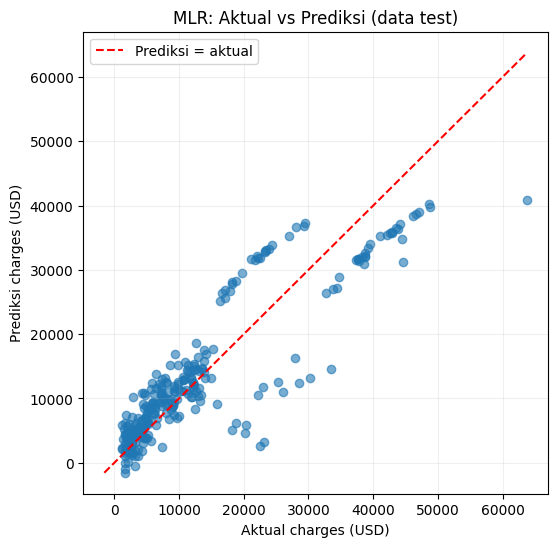

In [ ]:
# Cell 19: aktual vs prediksi
batas = [min(y_test_mlr.min(), y_pred_mlr.min()), max(y_test_mlr.max(), y_pred_mlr.max())]

plt.figure(figsize=(6, 6))
plt.scatter(y_test_mlr, y_pred_mlr, alpha=0.6)
plt.plot(batas, batas, color="red", linestyle="--", label="Prediksi = aktual")
plt.xlabel("Aktual charges (USD)")
plt.ylabel("Prediksi charges (USD)")
plt.title("MLR: Aktual vs Prediksi (data test)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Insight:**
- Untuk biaya rendah (di bawah sekitar 15.000 USD), titik berkumpul dekat garis merah. Tebakan cukup akurat pada kelompok yang paling banyak jumlahnya.
- Untuk biaya menengah sampai tinggi (sekitar 20.000 sampai 50.000 USD), hampir semua titik berada di **bawah** garis. Model cenderung memprediksi terlalu rendah.
- Sebagian titik meleset jauh: pelanggan dengan biaya aktual sekitar 20.000 sampai 33.000 USD diprediksi hanya sekitar 3.000 sampai 15.000 USD. Biaya tertinggi (sekitar 63.800 USD) diprediksi sekitar 41.000 USD.
- Beberapa prediksi bernilai di bawah 0 USD. Ini kelemahan model linear, karena biaya asuransi tidak mungkin negatif.

### 21b. Residual vs fitted dan Q-Q plot
- **Residual vs fitted:** cari pola (melengkung, melebar seperti corong, atau berkelompok). Awan acak di sekitar nol adalah kondisi yang diharapkan.
- **Q-Q plot:** jika residual mendekati normal, titik mengikuti garis lurus. Penyimpangan di ujung berarti ekor distribusi berbeda dari normal.

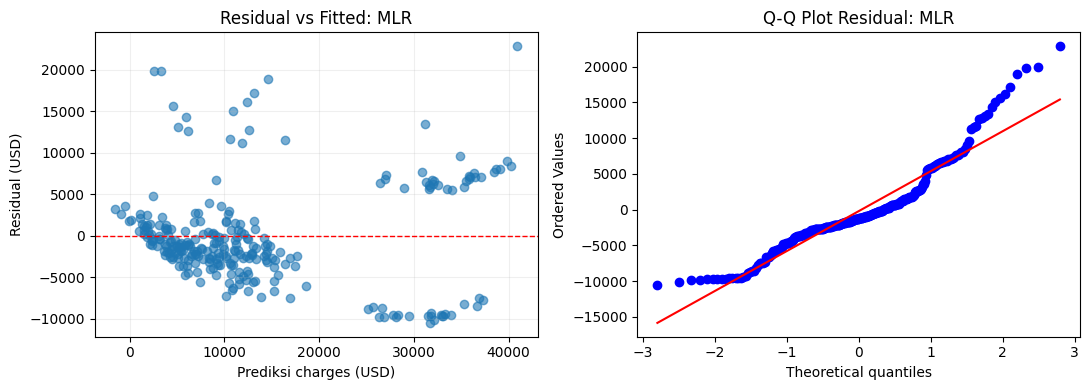

Residual rata-rata pada test: -219.24 USD


In [ ]:
# Cell 20: residual vs fitted dan Q-Q plot
from scipy import stats

resid_mlr = y_test_mlr.to_numpy() - y_pred_mlr

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_pred_mlr, resid_mlr, alpha=0.6)
ax[0].axhline(0, color="red", linestyle="--", linewidth=1)
ax[0].set(xlabel="Prediksi charges (USD)", ylabel="Residual (USD)",
          title="Residual vs Fitted: MLR")
ax[0].grid(alpha=0.2)

stats.probplot(resid_mlr, dist="norm", plot=ax[1])
ax[1].set_title("Q-Q Plot Residual: MLR")
plt.tight_layout()
plt.show()

print("Residual rata-rata pada test:", round(float(resid_mlr.mean()), 2), "USD")

**Insight:**
- Residual **tidak** membentuk awan acak di sekitar nol. Titik berkelompok.
- Pada prediksi rendah (sekitar 0 sampai 17.000 USD), sebagian besar residual berada di antara −7.000 dan +3.000 USD, tetapi ada kelompok titik dengan residual +10.000 sampai +20.000 USD. Pada kelompok itu model memprediksi terlalu rendah.
- Pada prediksi tinggi (sekitar 28.000 sampai 41.000 USD, yang dicapai karena koefisien `smoker_yes`), residual terpecah menjadi dua kelompok: sekitar +5.000 sampai +9.000 USD dan sekitar −8.000 sampai −10.000 USD. Ada perbedaan antar pelanggan yang belum ditangkap model.
- Dugaan: efek variabel lain (misalnya BMI) berbeda antara perokok dan bukan perokok, sedangkan model mengasumsikan efek yang sama. Dugaan ini bisa diuji dengan interaksi `smoker × bmi`, yang kita catat sebagai saran lanjutan.
- **Q-Q plot:** bagian tengah mendekati garis, tetapi kedua ujung menyimpang. Ekor kanan naik jauh di atas garis (sampai sekitar +23.000 USD), sedangkan ekor kiri mendatar di sekitar −10.000 USD. Residual miring ke kanan dan tidak normal.
- Residual rata-rata −219,24 USD, dekat nol dibanding sebaran residual. Karena residual tidak normal, selang kepercayaan atau uji yang mengandalkan normalitas tidak boleh dipakai begitu saja. Plot ini pemeriksaan visual, bukan bukti formal.

### 21c. Interpretasi Asumsi dari Plot Diagnostik

**1. Normalitas error (Q-Q Plot)**

Bagian tengah titik pada Q-Q Plot cukup dekat dengan garis, tetapi kedua ekor menyimpang. Ekor kanan menyimpang lebih jauh, sehingga residual menunjukkan kemencengan ke kanan. Dengan demikian, residual belum mengikuti distribusi normal secara memadai.

**2. Homoskedastisitas (Residual vs Fitted)**

Residual membentuk kelompok dan tidak menyebar sebagai awan acak yang merata di sekitar nol. Pola ini menunjukkan kemungkinan varians residual yang tidak konstan atau adanya pola lain yang belum dijelaskan model. Secara visual, asumsi homoskedastisitas belum dapat dianggap terpenuhi. Pemeriksaan ini bersifat visual, bukan uji formal seperti Breusch-Pagan.

### 21d. Uji Multikolinearitas (VIF)

VIF dihitung pada fitur training setelah One-Hot Encoding. Nilai VIF yang tinggi menunjukkan suatu prediktor dapat dijelaskan secara linear oleh prediktor lainnya.

In [ ]:
# Cell tambahan: hitung VIF dari fitur training hasil encoding
X_vif = prep.transform(X_train_mlr)

# Pastikan bentuk data berupa array NumPy dense.
if hasattr(X_vif, "toarray"):
    X_vif = X_vif.toarray()
X_vif = np.asarray(X_vif)

nama_fitur_vif = [
    nama.split("__", 1)[1] for nama in prep.get_feature_names_out()
]

# VIF adalah diagonal dari invers matriks korelasi antar-prediktor.
matriks_korelasi_prediktor = np.corrcoef(X_vif, rowvar=False)
nilai_vif = np.diag(np.linalg.inv(matriks_korelasi_prediktor))

tabel_vif = pd.DataFrame({
    "Fitur": nama_fitur_vif,
    "VIF": nilai_vif
}).sort_values("VIF", ascending=False)

tabel_vif.round(4)

**Interpretasi VIF:** seluruh nilai VIF berada pada kisaran rendah, sekitar 1,00 sampai 1,61, dan tidak ada yang mendekati batas praktis 5. Hasil ini tidak menunjukkan multikolinearitas yang mengkhawatirkan di antara prediktor pada data training. Penggunaan `drop="first"` sebelumnya menghindari multikolinearitas sempurna akibat dummy variable trap, sedangkan VIF memeriksa hubungan linear antarsemua prediktor.

### 21e. Uji Autokorelasi (Durbin-Watson)

Durbin-Watson dihitung dari residual data training. Residual diurutkan kembali berdasarkan indeks baris asli agar urutannya konsisten dengan dataset, bukan berdasarkan urutan acak hasil train-test split.

In [ ]:
# Cell tambahan: hitung Durbin-Watson dari residual training
prediksi_train = model_mlr.predict(X_train_mlr)
residual_train = pd.Series(
    y_train_mlr.to_numpy() - prediksi_train,
    index=X_train_mlr.index
).sort_index().to_numpy()

durbin_watson = (
    np.sum(np.diff(residual_train) ** 2) /
    np.sum(residual_train ** 2)
)

print("Durbin-Watson:", round(float(durbin_watson), 4))

**Interpretasi Durbin-Watson:** nilai sekitar 2,12 berada dekat dengan angka 2, sehingga tidak menunjukkan autokorelasi orde pertama yang kuat berdasarkan pedoman umum. Namun, dataset ini merupakan data cross-sectional antarindividu dan tidak memiliki urutan waktu. Karena itu, urutan baris bukan urutan temporal yang bermakna; hasil Durbin-Watson hanya bersifat indikatif dan tidak cukup untuk memastikan independensi error.

### 21f. Outlier pada residual
Residual dengan nilai mutlak sangat besar menandakan pelanggan yang tebakannya meleset jauh. Batas yang dipakai: standar skor residual melebihi 3 (|z| > 3).

Jumlah residual dengan |z| > 3: 4 dari 268


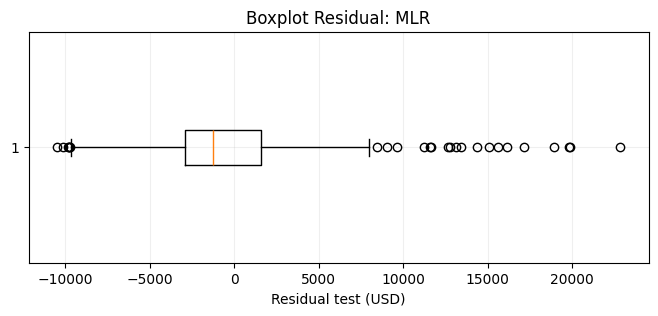

,age,sex,bmi,children,smoker,region,aktual,prediksi,residual
543,54,female,47.410,0,yes,southeast,63770.42801,40920.29,22850.14
1039,19,male,27.265,2,no,northwest,22493.65964,2603.44,19890.22
430,19,male,33.100,0,no,southwest,23082.95533,3280.69,19802.26
599,52,female,37.525,2,no,northwest,33471.97189,14560.80,18911.18
115,60,male,28.595,0,no,northeast,30259.99556,13107.89,17152.10


In [ ]:
# Cell 21: deteksi outlier residual
z = (resid_mlr - resid_mlr.mean()) / resid_mlr.std()
print("Jumlah residual dengan |z| > 3:", int((np.abs(z) > 3).sum()), "dari", len(z))

plt.figure(figsize=(8, 3))
plt.boxplot(resid_mlr, vert=False)
plt.xlabel("Residual test (USD)")
plt.title("Boxplot Residual: MLR")
plt.grid(alpha=0.2)
plt.show()

lima_terbesar = X_test_mlr.copy()
lima_terbesar["aktual"] = y_test_mlr
lima_terbesar["prediksi"] = y_pred_mlr.round(2)
lima_terbesar["residual"] = resid_mlr.round(2)
lima_terbesar.loc[lima_terbesar["residual"].abs().sort_values(ascending=False).index[:5]]

**Insight:**
- Dengan batas |z| > 3, ada **4 dari 268** residual outlier. Boxplot menandai lebih banyak titik di luar kotak, hampir semuanya di sisi kanan (residual positif sampai sekitar 23.000 USD).
- Kelima residual terbesar semuanya **positif**, artinya model memprediksi terlalu rendah.
- Empat dari lima pelanggan itu bukan perokok dengan biaya aktual 22.000 sampai 33.000 USD, tetapi diprediksi hanya sekitar 2.600 sampai 14.600 USD. Pelanggan dengan residual terbesar adalah perokok berusia 54 tahun dengan BMI 47,4. Biayanya 63.770 USD dan diprediksi 40.921 USD, meleset sekitar 22.850 USD.
- Kemungkinan penyebab: faktor yang tidak ada di dataset (misalnya riwayat penyakit) dan efek gabungan `smoker` dengan BMI tinggi yang tidak ditangkap model aditif. Ini dugaan, belum diuji.
- Outlier ini nilai yang nyata, bukan kesalahan data, jadi tidak dibuang. Hanya dicatat sebagai keterbatasan.

## 22. Kesimpulan
**Perbandingan:** SLR (hanya `age`) mencapai R² = 0,1241, MAE = 9.173 USD, dan RMSE = 11.661 USD. MLR (6 prediktor) mencapai R² = 0,7836, MAE = 4.181 USD, dan RMSE = 5.796 USD pada test set yang sama.

**Temuan utama:**
1. Menambah prediktor memperbaiki prediksi dengan jelas. Dugaan dari scatter SLR bahwa ada faktor lain di balik tiga pita biaya terbukti di model berganda. Faktor terbesar adalah status merokok: perokok diprediksi membayar sekitar 23.651 USD lebih tinggi daripada bukan perokok pada kondisi variabel lain yang sama, jauh di atas efek usia (sekitar 257 USD per tahun) atau BMI (sekitar 337 USD per poin).
2. Koefisien dibaca sebagai asosiasi bersyarat terhadap kategori referensi, bukan sebab-akibat.

**Keterbatasan:**
1. Data observasional dan hasil berasal dari satu kali split 80:20. Hasil bisa bergeser pada split lain.
2. Model linear menganggap efek setiap prediktor bersifat aditif. Pola di plot diagnostik perlu dibaca untuk melihat apakah anggapan ini cukup.
3. `charges` miring ke kanan, jadi kesalahan prediksi cenderung besar pada biaya tinggi.
4. Dataset publik tanpa penjelasan rinci cara pengumpulannya. Hasil tidak boleh digeneralisasi ke populasi lain.

**Lanjutan yang mungkin:** transformasi log pada `charges`, interaksi `smoker × bmi`, atau validasi silang.

## 23. Referensi dan Catatan
- Lantz, B. *Machine Learning with R*. Packt Publishing. Dataset versi Kaggle: `mirichoi0218/insurance`.
- Dokumentasi scikit-learn: `LinearRegression`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline`, `train_test_split`.